# Scan Path Loop Prototype

```
  1 path generator  →  2 instrument model  →  3 evaluator  →  4 optimization
         ↑                                                         │
         └──────────────── next parameters (from the run log) ─────────┘
```


**What is passed between modules**

| between | object |
|---|---|
| start → end  | a **path**: a dict `{name, family, params, x, y, t}` (metres, seconds) |
| Instrument Model → Evaluator | same dict, distorted path, plus `info` (instrument report) |
| Evaluator → Optimization (Loop) | a dict of quality scores `{metric: value}` |
| Optimization (Loop) → path generator | `{family, params}` — read back from the log |

Everything a person needs to follow the run goes into **`run_log.yaml`**, which starts
empty and grows one section per step. The coordinate arrays go into **`paths.npz`**,
referenced in the log.

Each section below would map to one file in the repository (`paths/`, `instrument.py`,
`evaluate.py`, `optimize.py`).

## 0. Setup and the shared budget

Every path gets the **same budget**, meaning the same number of samples, spacing, speed, scan time and length, and the same motion limits. Each family has one *knob* that is tuned to hit the budget.


In [ ]:
import math, itertools, numpy as np, yaml, matplotlib.pyplot as plt
from scipy.signal import lfilter

FIELD    = 20e-6            # m, square scan field
STEP     = 100e-9           # m, spacing between samples while moving
SPEED    = 20e-6            # m/s, the same for every path
DT       = STEP / SPEED     # s per sample
N_BUDGET = 12_800           # samples  ->  64 s and ~1280 µm for every path
R = FIELD / 2

LOG = {}                    # the run log - starts with nothing
def r4(v):                  # every number in the log is a float, 4 sig figs
    return {k: r4(x) for k, x in v.items()} if isinstance(v, dict) else float(f"{v:.4g}")
def show(section):
    print(yaml.safe_dump({section: LOG[section]}, sort_keys=False, width=100))

INK, MUTED, GRID, C_PATH, C_DIST = "#1b1d21", "#7b838f", "#e3e5e9", "#4b525c", "#c2610a"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                     "axes.edgecolor": GRID, "text.color": INK, "font.size": 9,
                     "xtick.color": MUTED, "ytick.color": MUTED, "figure.dpi": 110})

LOG["run"] = dict(budget=dict(samples=r4(N_BUDGET), step_nm=r4(STEP*1e9), speed_um_s=r4(SPEED*1e6),
                              time_s=r4(N_BUDGET*DT), length_um=r4(N_BUDGET*STEP*1e6),
                              field_um=r4(FIELD*1e6)))
show("run")

run:
  budget:
    samples: 12800.0
    step_nm: 100.0
    speed_um_s: 20.0
    time_s: 64.0
    length_um: 1280.0
    field_um: 20.0



## 1. Path generator

Two separate jobs:

* **Adding a family** (rare): one function that draws the shape for a given *density*.
* **Adding a path** (often): one line — a name and its family.

`make_path(name, family, **settings)` is the only way to get a path. It tunes the family's
density (its knob) until the path has the budgeted number of samples, rotates it if asked,
and returns the path dict.

In [ ]:
FAMILIES = {}

def family(free=None, **defaults):
    """Register a family. free: settings the optimizer may vary (default: rotation)."""
    def deco(fn):
        FAMILIES[fn.__name__] = dict(fn=fn, defaults=defaults,
                                     free=free or dict(angle_deg=np.linspace(0, 45, 10)))
        return fn
    return deco

def densify(px, py):
    """Any polyline -> one sample every STEP along it. Every family ends here."""
    px, py = np.asarray(px, float), np.asarray(py, float)
    s = np.concatenate([[0], np.cumsum(np.hypot(np.diff(px), np.diff(py)))])
    si = np.arange(0, s[-1] + STEP / 2, STEP)
    return np.interp(si, s, px), np.interp(si, s, py)

def make_path(name, family, angle_deg=0.0, **settings):
    F = FAMILIES[family]
    settings.pop("density", None)                   # always re-tuned, never taken as given
    s = {**F["defaults"], **settings}
    density, best = 50.0, None
    for _ in range(8):                              # tune the density until the budget fits
        x, y = F["fn"](density, **s)
        if best is None or abs(x.size - N_BUDGET) < abs(best[0].size - N_BUDGET):
            best = (x, y, density)
        density *= N_BUDGET / x.size
    x, y, density = best
    c, si = math.cos(math.radians(angle_deg)), math.sin(math.radians(angle_deg))
    return dict(name=name, family=family, params=dict(density=density, angle_deg=angle_deg, **s),
                x=c*x - si*y, y=si*x + c*y, t=np.arange(x.size) * DT)

**The seven families.** Each cell below would be one file in `paths/`. Adding a family is
adding one more cell like these: a function plus its `@family(...)` line. A family only draws
its shape; matching the budget and rotating are done for it.

In [ ]:
# paths/raster.py
def _raster_corners(n_lines, half):
    ys = np.linspace(-half, half, int(n_lines))
    xs = np.ravel([(-half, half) if i % 2 == 0 else (half, -half) for i in range(int(n_lines))])
    return xs, np.repeat(ys, 2)


@family()
def raster(density):                      # density = number of lines
    return densify(*_raster_corners(round(density), R))

In [ ]:
# paths/spiral.py
@family()
def spiral(density):                      # density = number of turns
    th = np.linspace(0, 2*np.pi*density, 40_000)
    return densify(R*th/th[-1]*np.cos(th), R*th/th[-1]*np.sin(th))

In [ ]:
# paths/lissajous.py
@family(free=dict(d=np.arange(1, 7), phase_deg=np.linspace(0, 90, 10)), d=1, phase_deg=90.0)
def lissajous(density, d, phase_deg):     # density = x frequency
    u, n1 = np.linspace(0, 2*np.pi, 60_000), round(density)
    return densify(R*np.sin(n1*u + math.radians(phase_deg)), R*np.sin((n1 + d)*u))

In [ ]:
# paths/radial.py
@family()
def radial(density):                      # density = number of spokes
    a = 2*np.pi*np.arange(round(density)) / round(density)
    return densify(np.ravel(np.column_stack([0*a, R*np.cos(a), 0*a])),
                   np.ravel(np.column_stack([0*a, R*np.sin(a), 0*a])))

In [ ]:
# paths/hilbert.py
@family()
def hilbert(density):                     # density = cells across (rounded to a power of 2)
    p = np.array([[0.5, 0.5]])
    for _ in range(round(math.log2(density))):
        p = p / 2
        p = np.concatenate([p[:, ::-1], p + [0, 0.5], p + [0.5, 0.5], [1, 0.5] - p[:, ::-1]])
    return densify(*(p * FIELD - R).T)

In [ ]:
# paths/sparse.py
@family(free=dict(n_points=np.array([16, 25, 36, 49, 64, 81, 100])), n_points=64)
def sparse(density, n_points):            # density = samples spent at each point
    k = round(math.sqrt(n_points)); c = FIELD / k
    gx, gy = np.meshgrid((np.arange(k) + 0.5) * c - R, (np.arange(k) + 0.5) * c - R)
    gx[1::2] = gx[1::2, ::-1]                                       # serpentine order
    p = np.column_stack([gx.ravel(), gy.ravel()])
    p += np.random.default_rng(0).uniform(-0.35, 0.35, p.shape) * c
    xs, ys = [], []
    for a, b in zip(p[:-1], p[1:]):                                 # dwell, then travel
        tx, ty = densify([a[0], b[0]], [a[1], b[1]])
        xs += [np.full(round(density), a[0]), tx]; ys += [np.full(round(density), a[1]), ty]
    return np.concatenate(xs), np.concatenate(ys)

In [ ]:
# paths/hybrid.py
@family(free=dict(roi_frac=np.linspace(0.2, 0.6, 9)), roi_frac=0.4)
def hybrid(density, roi_frac):            # density = lines in the fine region
    cx, cy = _raster_corners(32, R)
    fx, fy = _raster_corners(round(density), R * roi_frac)
    return densify(np.concatenate([cx, fx]), np.concatenate([cy, fy]))

**The paths.** Adding a path is adding one line: a name and its family, like adding an
image and labelling it. Every path is matched to the same budget automatically.

The input image is a synthetic sample with eight small features at known positions.

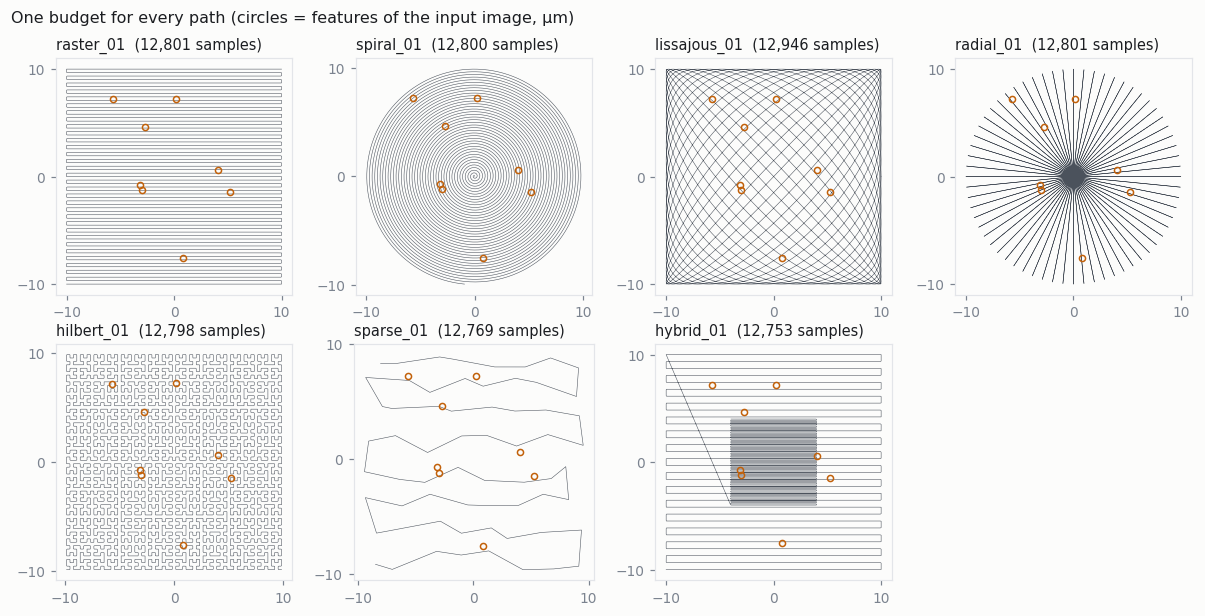

stage_1_paths:
- name: raster_01
  family: raster
  params:
    density: 62.74
    angle_deg: 0.0
  samples: 12800.0
  time_s: 64.0
  input_image: sample.npz  (synthetic_blobs, 8 features)
  arrays: 'paths.npz :: raster_01'
- name: spiral_01
  family: spiral
  params:
    density: 40.74
    angle_deg: 0.0
  samples: 12800.0
  time_s: 63.99
  input_image: sample.npz  (synthetic_blobs, 8 features)
  arrays: 'paths.npz :: spiral_01'
- name: lissajous_01
  family: lissajous
  params:
    density: 21.05
    angle_deg: 0.0
    d: 1.0
    phase_deg: 90.0
  samples: 12950.0
  time_s: 64.72
  input_image: sample.npz  (synthetic_blobs, 8 features)
  arrays: 'paths.npz :: lissajous_01'
- name: radial_01
  family: radial
  params:
    density: 63.99
    angle_deg: 0.0
  samples: 12800.0
  time_s: 64.0
  input_image: sample.npz  (synthetic_blobs, 8 features)
  arrays: 'paths.npz :: radial_01'
- name: hilbert_01
  family: hilbert
  params:
    density: 50.0
    angle_deg: 0.0
  samples: 12800.0
  ti

In [ ]:
PATHS = {                    # name: family   <- to add a path, add a line
    "raster_01":    "raster",
    "spiral_01":    "spiral",
    "lissajous_01": "lissajous",
    "radial_01":    "radial",
    "hilbert_01":   "hilbert",
    "sparse_01":    "sparse",
    "hybrid_01":    "hybrid",
}
paths = [make_path(name, fam) for name, fam in PATHS.items()]

rng = np.random.default_rng(1)
SAMPLE = dict(name="synthetic_blobs", features=rng.uniform(-0.8*R, 0.8*R, (8, 2)), size=300e-9)
np.savez("sample.npz", features=SAMPLE["features"], size=SAMPLE["size"])

rows = math.ceil(len(paths) / 4)
fig, axes = plt.subplots(rows, 4, figsize=(11, 2.8 * rows), squeeze=False)
for ax in axes.ravel()[len(paths):]:
    ax.axis("off")
for ax, p in zip(axes.ravel(), paths):
    ax.plot(p["x"]*1e6, p["y"]*1e6, lw=0.35, color=C_PATH)
    ax.plot(*(SAMPLE["features"].T * 1e6), "o", ms=4, mfc="none", mec=C_DIST)
    ax.set_title(f"{p['name']}  ({p['x'].size:,} samples)", loc="left", fontsize=9.5)
    ax.set_aspect("equal"); ax.set_xticks([-10, 0, 10]); ax.set_yticks([-10, 0, 10])
plt.suptitle("One budget for every path (circles = features of the input image, µm)",
             x=0.01, ha="left", fontsize=10.5)
plt.tight_layout(); plt.show()

LOG["stage_1_paths"] = [dict(
    name=p["name"], family=p["family"],
    params=r4(p["params"]),
    samples=r4(p["x"].size), time_s=r4(p["t"][-1]),
    input_image="sample.npz  (synthetic_blobs, 8 features)",
    arrays=f"paths.npz :: {p['name']}") for p in paths]
show("stage_1_paths")

## 2. Instrument model: path → distorted path

The instrument is a **list of stages applied in order**. Each stage is a function
`stage(x, y, t, rng) -> (x, y, info)`. To add a stage, insert it where you want it to be used —
before or after any other stage.

**Base functions** work for every model: `@stage(label)` turns a plain function into a named
stage, `run_instrument` applies the stages in order, and `rms_nm` compares two paths. A new
model only needs these.

In [ ]:
def stage(label):
    """Base: turn any function f(x, y, t, rng) -> (x, y, info) into a named stage."""
    def deco(fn):
        fn.label = label
        return fn
    return deco

def run_instrument(path, stages=None, seed=0):
    """Base: apply the stages in order. The same for every model."""
    rng, x, y, info = np.random.default_rng(seed), path["x"], path["y"], {}
    for st in (INSTRUMENT if stages is None else stages):
        x, y, i = st(x, y, path["t"], rng); info.update(i)
    return {**path, "x": x, "y": y, "info": info}

def rms_nm(a, b):
    """Base: RMS distance between two paths, nm."""
    return float(np.sqrt(np.mean((a["x"]-b["x"])**2 + (a["y"]-b["y"])**2)) * 1e9)

**Model 1: Switching confidence** is the probability the scan finishes without any coarse stage
move landing further than 100 nm from its target, `(1 − p_bad)^moves`. The path with
the highest confidence is stored and moves onto the evaluator part.

These functions are used only by the switching model.

In [ ]:
R_FINE, LANDING_SD, LANDING_TOL = 5e-6, 50e-9, 100e-9

def move_points(x, y, r_fine=R_FINE):
    """Switching: sample indices where the path leaves the piezo window, so the stage moves."""
    idx, x0, x1, y0, y1 = [], x[0], x[0], y[0], y[0]
    for i in range(1, x.size):
        x0, x1, y0, y1 = min(x0, x[i]), max(x1, x[i]), min(y0, y[i]), max(y1, y[i])
        if x1 - x0 > 2*r_fine or y1 - y0 > 2*r_fine:
            idx.append(i); x0 = x1 = x[i]; y0 = y1 = y[i]
    return np.array(idx, int)

def stage_moves(r_fine=R_FINE, landing_sd=LANDING_SD):
    """Switching as a stage: after each move, everything is offset by that move's landing error."""
    @stage(f"stage_moves(r_fine_um={r_fine*1e6:g}, landing_sd_nm={landing_sd*1e9:g})")
    def apply(x, y, t, rng):
        idx = move_points(x, y, r_fine)
        land = np.vstack([[0, 0], rng.normal(0, landing_sd, (idx.size, 2))])
        off = land[np.searchsorted(idx, np.arange(x.size), side="right")]
        return x + off[:, 0], y + off[:, 1], {"stage_moves": int(idx.size)}
    return apply

def switch_confidence(moves):
    """Switching: probability that no stage move lands more than LANDING_TOL off target."""
    p_bad = math.exp(-LANDING_TOL**2 / (2 * LANDING_SD**2))     # Rayleigh tail
    return (1 - p_bad) ** moves

def most_confident(paths, distorted):
    """Switching: index of the path with the highest confidence (ties: smaller RMS distortion)."""
    conf = [switch_confidence(d["info"]["stage_moves"]) for d in distorted]
    return max(range(len(paths)), key=lambda i: (round(conf[i], 6), -rms_nm(paths[i], distorted[i]))), conf

**Other effects.** Each is a few lines built from the base functions, and the instrument is
just the list of them, in order.

In [ ]:
def lag(tau=5e-3):
    """Piezo servo as a first-order low-pass: lags on lines, cuts corners."""
    a = math.exp(-DT / tau)
    @stage(f"lag(tau_s={tau})")
    def apply(x, y, t, rng):
        f = lambda v: lfilter([1 - a], [1, -a], v - v[0]) + v[0]
        return f(x), f(y), {}
    return apply

def drift(vx=2e-9, vy=1e-9):
    @stage(f"drift(nm_per_s=({vx*1e9:g}, {vy*1e9:g}))")
    def apply(x, y, t, rng):
        return x + vx*t, y + vy*t, {}
    return apply

def noise(sd=2e-9):
    @stage(f"noise(sd_nm={sd*1e9:g})")
    def apply(x, y, t, rng):
        return x + rng.normal(0, sd, x.size), y + rng.normal(0, sd, y.size), {}
    return apply

INSTRUMENT = [lag(), stage_moves(), drift(), noise()]

stage_2_instrument:
  model:
  - lag(tau_s=0.005)
  - stage_moves(r_fine_um=5, landing_sd_nm=50)
  - drift(nm_per_s=(2, 1))
  - noise(sd_nm=2)
  paths:
  - name: raster_01
    distorted: 'paths.npz :: raster_01_distorted'
    stage_moves: 63.0
    switch_confidence: 0.0001051
    rms_distortion_nm: 123.8
  - name: spiral_01
    distorted: 'paths.npz :: spiral_01_distorted'
    stage_moves: 70.0
    switch_confidence: 3.796e-05
    rms_distortion_nm: 119.7
  - name: lissajous_01
    distorted: 'paths.npz :: lissajous_01_distorted'
    stage_moves: 83.0
    switch_confidence: 5.733e-06
    rms_distortion_nm: 121.9
  - name: radial_01
    distorted: 'paths.npz :: radial_01_distorted'
    stage_moves: 3.0
    switch_confidence: 0.6465
    rms_distortion_nm: 106.1
  - name: hilbert_01
    distorted: 'paths.npz :: hilbert_01_distorted'
    stage_moves: 3.0
    switch_confidence: 0.6465
    rms_distortion_nm: 101.6
  - name: sparse_01
    distorted: 'paths.npz :: sparse_01_distorted'
    stag

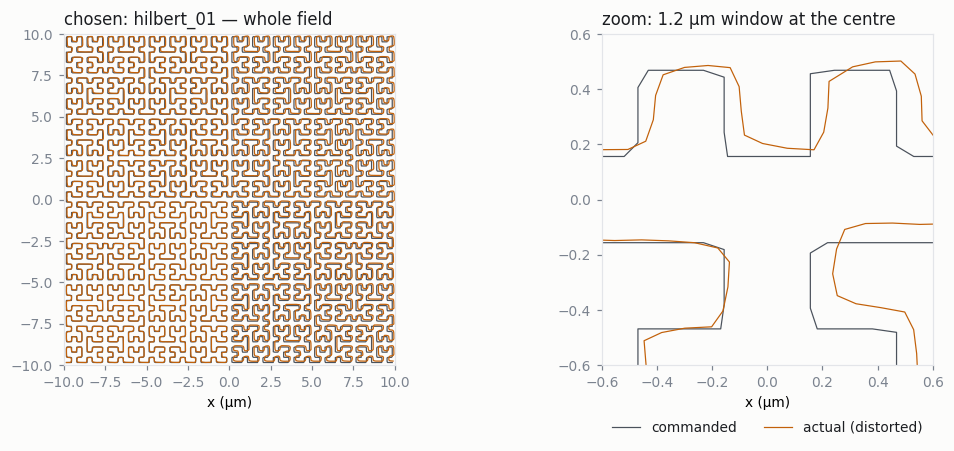

In [ ]:
distorted = [run_instrument(p) for p in paths]
i_best, conf = most_confident(paths, distorted)
chosen, chosen_d = paths[i_best], distorted[i_best]

np.savez("paths.npz", **{p["name"]: np.vstack([p["x"], p["y"]]) for p in paths},
         **{p["name"] + "_distorted": np.vstack([d["x"], d["y"]]) for p, d in zip(paths, distorted)})

LOG["stage_2_instrument"] = dict(
    model=[st.label for st in INSTRUMENT],
    paths=[dict(name=p["name"], distorted=f"paths.npz :: {p['name']}_distorted",
                stage_moves=r4(d["info"]["stage_moves"]), switch_confidence=r4(c),
                rms_distortion_nm=r4(rms_nm(p, d)))
           for p, d, c in zip(paths, distorted, conf)],
    chosen=chosen["name"])
show("stage_2_instrument")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, half in zip(axes, (R, 0.6e-6)):
    ax.plot(chosen["x"]*1e6, chosen["y"]*1e6, lw=0.8, color=C_PATH, label="commanded")
    ax.plot(chosen_d["x"]*1e6, chosen_d["y"]*1e6, lw=0.8, color=C_DIST, label="actual (distorted)")
    ax.set_xlim(-half*1e6, half*1e6); ax.set_ylim(-half*1e6, half*1e6); ax.set_aspect("equal")
    ax.set_xlabel("x (µm)")
axes[0].set_title(f"chosen: {chosen['name']} — whole field", loc="left")
axes[1].set_title("zoom: 1.2 µm window at the centre", loc="left")
axes[1].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
plt.tight_layout(); plt.show()

## 3. Evaluator

One evaluator with multple quality functions. Each quality function starts with a header of this format: **name, unit, weight (%)** in the objective, and one line on what it measures.
Adding a quality function is just adding one more block like these `evaluate` will pick up on it.

Every function sees the same three things: the commanded path, distorted path, and
a context (`sample` = the input image, `rerun(seed)` = reproducibly run the instrument again).

In [ ]:
QUALITY = {}
def quality(name, unit, weight, about):
    def deco(fn):
        QUALITY[fn.__name__] = dict(fn=fn, name=name, unit=unit, weight=weight, about=about)
        return fn
    return deco

def _gap(a, b):
    return np.hypot(a["x"] - b["x"], a["y"] - b["y"])

@quality(name="Global trajectory distortion", unit="nm", weight=0,
         about="RMS distance between commanded and actual, over the whole scan")
def global_distortion(ideal, dist, ctx):
    return float(np.sqrt(np.mean(_gap(ideal, dist)**2)) * 1e9)

@quality(name="Local misalignment", unit="nm", weight=0,
         about="RMS left after removing the best overall shift and rotation (shape error)")
def local_misalignment(ideal, dist, ctx):
    P = np.column_stack([ideal["x"], ideal["y"]]); Q = np.column_stack([dist["x"], dist["y"]])
    P, Q = P - P.mean(0), Q - Q.mean(0)
    U, _, Vt = np.linalg.svd(Q.T @ P)
    return float(np.sqrt(np.mean(np.sum((Q @ U @ Vt - P)**2, 1))) * 1e9)

@quality(name="Noise sensitivity", unit="nm", weight=0,
         about="RMS change in the actual path between repeat runs of the same command")
def noise_sensitivity(ideal, dist, ctx):
    return float(np.mean([np.sqrt(np.mean(_gap(dist, ctx["rerun"](s))**2)) for s in (101, 102)]) * 1e9)

@quality(name="Placement error", unit="nm", weight=0,
         about="99th percentile of |actual − recorded|: the worst-placed samples")
def placement_error(ideal, dist, ctx):
    return float(np.percentile(_gap(ideal, dist), 99) * 1e9)

@quality(name="Feature-position error", unit="nm", weight=100,
         about="how far each feature appears from where a perfect instrument would put it")
def feature_position_error(ideal, dist, ctx):
    f, s, errs = ctx["sample"]["features"], ctx["sample"]["size"], []
    for fx, fy in f:
        w0 = np.exp(-((ideal["x"]-fx)**2 + (ideal["y"]-fy)**2) / (2*s*s))   # perfect scan sees it here
        w1 = np.exp(-((dist["x"]-fx)**2 + (dist["y"]-fy)**2) / (2*s*s))     # this scan sees it here
        if w0.sum() > 1e-3 and w1.sum() > 1e-3:          # skip features the path never visits
            a0 = np.array([w0 @ ideal["x"], w0 @ ideal["y"]]) / w0.sum()
            a1 = np.array([w1 @ ideal["x"], w1 @ ideal["y"]]) / w1.sum()   # ...but records it here
            errs.append(np.hypot(*(a1 - a0)))
    return float(np.mean(errs) * 1e9) if errs else float("nan")

In [ ]:
def evaluate(ideal, dist, stages=None):
    ctx = dict(sample=SAMPLE, rerun=lambda s: run_instrument(ideal, stages, seed=s))
    return {k: q["fn"](ideal, dist, ctx) for k, q in QUALITY.items()}

def objective(scores, reference):
    """Weighted sum, each metric relative to the reference path. Weights in %."""
    return sum(q["weight"] / 100 * scores[k] / reference[k] for k, q in QUALITY.items() if q["weight"])

scores = evaluate(chosen, chosen_d)
LOG["stage_3_evaluation"] = dict(path=chosen["name"], results={
    k: dict(name=QUALITY[k]["name"], value=r4(v), unit=QUALITY[k]["unit"],
            weight_pct=r4(QUALITY[k]["weight"])) for k, v in scores.items()})
show("stage_3_evaluation")

print("For comparison, every path (nm):")
print(f"{'path':<14}" + "".join(f"{k[:13]:>15}" for k in QUALITY))
for p, d in zip(paths, distorted):
    print(f"{p['name']:<14}" + "".join(f"{v:>15.1f}" for v in evaluate(p, d).values()))

stage_3_evaluation:
  path: hilbert_01
  results:
    global_distortion:
      name: Global trajectory distortion
      value: 101.6
      unit: nm
      weight_pct: 0.0
    local_misalignment:
      name: Local misalignment
      value: 67.96
      unit: nm
      weight_pct: 0.0
    noise_sensitivity:
      name: Noise sensitivity
      value: 61.61
      unit: nm
      weight_pct: 0.0
    placement_error:
      name: Placement error
      value: 181.1
      unit: nm
      weight_pct: 0.0
    feature_position_error:
      name: Feature-position error
      value: 73.8
      unit: nm
      weight_pct: 100.0

For comparison, every path (nm):
path            global_distor  local_misalig  noise_sensiti  placement_err  feature_posit
raster_01               123.8           94.1          100.2          252.9           76.8
spiral_01               119.7           75.0           85.3          275.2           93.0
lissajous_01            121.9           98.2           97.7          221.2       

## 4. Optimization loop: grid search within the chosen family

Every point on the grid of the family's free parameters is generated using the same
budget, distorted and evaluated. The instrument is random (noise and stage landings), so
every grid point is run with the **same 16 seeds** and compared with the default path
**seed by seed**.

**Decision rule:** move to the best grid point only if its improvement is larger than
twice its standard error. Otherwise, keep the current parameters — the loop should not
chase noise.

stage_4_optimization:
  family: hilbert
  objective:
    feature_position_error: 100.0
  method: grid over ['angle_deg'], 16 paired seeds per point
  start:
    params:
      angle_deg: 0.0
    objective: 1.0
  grid:
  - params:
      angle_deg: 0.0
    change: 0.0
    sem: 0.0
  - params:
      angle_deg: 5.0
    change: 0.0911
    sem: 0.06429
  - params:
      angle_deg: 10.0
    change: 0.08917
    sem: 0.06967
  - params:
      angle_deg: 15.0
    change: 0.07279
    sem: 0.06512
  - params:
      angle_deg: 20.0
    change: 0.1118
    sem: 0.06298
  - params:
      angle_deg: 25.0
    change: 0.1293
    sem: 0.0655
  - params:
      angle_deg: 30.0
    change: 0.204
    sem: 0.076
  - params:
      angle_deg: 35.0
    change: 0.1762
    sem: 0.0725
  - params:
      angle_deg: 40.0
    change: 0.1928
    sem: 0.07653
  - params:
      angle_deg: 45.0
    change: 0.1873
    sem: 0.08337
  best:
    params:
      angle_deg: 0.0
    change: 0.0
    sem: 0.0
  decision: 'kept current

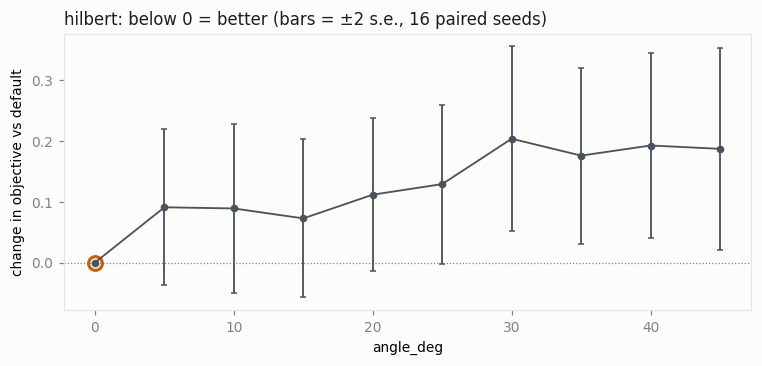

In [ ]:
SEEDS = range(16)
DEFAULT = {k: chosen["params"][k] for k in FAMILIES[chosen["family"]]["free"]}

def run_objective(path, seeds, reference):
    return np.array([objective(evaluate(path, run_instrument(path, seed=s)), reference) for s in seeds])

def optimize(family, base, reference, seeds=SEEDS):
    """Grid over the family's free parameters; each point compared with `base`, seed by seed."""
    free = FAMILIES[family]["free"]
    base_obj = run_objective(make_path("base", family, **base), seeds, reference)
    rows = []
    for values in itertools.product(*free.values()):
        params = dict(zip(free, (v.item() if hasattr(v, "item") else v for v in values)))
        diff = run_objective(make_path("grid", family, **params), seeds, reference) - base_obj
        rows.append(dict(params=params, change=float(diff.mean()),
                         sem=float(diff.std(ddof=1) / math.sqrt(len(diff)))))
    best = min(rows, key=lambda r: r["change"])
    accept = best["change"] + 2 * best["sem"] < 0
    return (best["params"] if accept else base), best, accept, rows

ref = {k: np.mean([evaluate(chosen, run_instrument(chosen, seed=s))[k] for s in SEEDS]) for k in QUALITY}
next_params, best, accepted, rows = optimize(chosen["family"], DEFAULT, ref)

LOG["stage_4_optimization"] = dict(
    family=chosen["family"],
    objective={k: r4(QUALITY[k]["weight"]) for k in QUALITY if QUALITY[k]["weight"]},
    method=f"grid over {list(DEFAULT)}, {len(SEEDS)} paired seeds per point",
    start=dict(params=r4(DEFAULT), objective=1.0),
    grid=[dict(params=r4(r["params"]), change=r4(r["change"]), sem=r4(r["sem"])) for r in rows],
    best=dict(params=r4(best["params"]), change=r4(best["change"]), sem=r4(best["sem"])),
    decision=("accepted: improvement larger than 2 s.e." if accepted
              else "kept current parameters: best improvement is within 2 s.e. (noise)"),
    next_input=dict(family=chosen["family"], params=r4(next_params)))
show("stage_4_optimization")

free = list(DEFAULT)
if len(free) == 1:
    xs = [r["params"][free[0]] for r in rows]
    fig, ax = plt.subplots(figsize=(7, 3.4))
    ax.axhline(0, color=MUTED, lw=0.8, ls=":")
    ax.errorbar(xs, [r["change"] for r in rows], yerr=[2*r["sem"] for r in rows], color=C_PATH,
                marker="o", ms=4, capsize=2, lw=1.2)
    ax.plot(best["params"][free[0]], best["change"], "o", ms=9, mfc="none", mec=C_DIST, mew=2)
    ax.set_xlabel(free[0]); ax.set_ylabel("change in objective vs default")
    ax.set_title(f"{chosen['family']}: below 0 = better (bars = ±2 s.e., {len(SEEDS)} paired seeds)",
                 loc="left")
    plt.tight_layout(); plt.show()

### Closing Loop

The run log is saved, read back from disk, and the generator would build the next path from
`next_input` alone. This is the whole interface: a YAML file and a `.npz` array file.

In [ ]:
with open("run_log.yaml", "w") as fh:
    yaml.safe_dump(LOG, fh, sort_keys=False, width=100)

nxt = yaml.safe_load(open("run_log.yaml"))["stage_4_optimization"]["next_input"]
p2 = make_path(f"{nxt['family']}_02", nxt["family"], **nxt["params"])
print(f"iteration 2 built from the log alone: {p2['name']} {nxt['params']}")

if nxt["params"] == r4(DEFAULT):
    print("the loop kept the current parameters, so iteration 2 repeats iteration 1")
else:
    # Confirm on NEW seeds: the grid chose its best point on SEEDS, so re-testing on the
    # same seeds would flatter it (the winner's curse).
    fresh = range(100, 116)
    d = run_objective(p2, fresh, ref) - run_objective(chosen, fresh, ref)
    print(f"change vs default on fresh seeds: {d.mean():+.3f} ± {d.std(ddof=1)/math.sqrt(len(d)):.3f}")

iteration 2 built from the log alone: hilbert_02 {'angle_deg': 0.0}
the loop kept the current parameters, so iteration 2 repeats iteration 1


## 5. Swapping modules without touching the workflow

**A new instrument stage**, inserted before or after any other. Here: piezo creep,
placed right after the servo lag. Nothing else changes.

In [ ]:
def creep(amount=0.01, tau=10.0):
    """Piezo creep: a slow extra extension after each move, as a fraction of it."""
    @stage(f"creep(amount={amount}, tau_s={tau})")
    def apply(x, y, t, rng):
        g = amount * (1 - np.exp(-t / tau))
        return x + g * (x - x[0]), y + g * (y - y[0]), {}
    return apply

with_creep = list(INSTRUMENT)
with_creep.insert(1, creep())                    # position 1 = right after lag; any index works
print("instrument:", [s.label for s in with_creep])
d_creep = run_instrument(chosen, with_creep)
print({k: round(v, 1) for k, v in evaluate(chosen, d_creep, with_creep).items()})

instrument: ['lag(tau_s=0.005)', 'creep(amount=0.01, tau_s=10.0)', 'stage_moves(r_fine_um=5, landing_sd_nm=50)', 'drift(nm_per_s=(2, 1))', 'noise(sd_nm=2)']
{'global_distortion': 236.7, 'local_misalignment': 125.1, 'noise_sensitivity': 61.6, 'placement_error': 408.5, 'feature_position_error': 204.4}


**A new quality function**: one more block with a header. It appears in every
evaluation from now on with weight 0 it is reported, but it does not change the loop.

In [ ]:
@quality(name="Coverage gap", unit="nm", weight=0,
         about="largest distance from any point of the field to the nearest actual sample")
def coverage_gap(ideal, dist, ctx):
    g = np.linspace(-0.95*R, 0.95*R, 40)
    gx, gy = [a.ravel() for a in np.meshgrid(g, g)]
    step = max(1, dist["x"].size // 4000)
    dx, dy = dist["x"][::step], dist["y"][::step]
    return float(max(np.min(np.hypot(dx - x, dy - y)) for x, y in zip(gx, gy)) * 1e9)

print({k: round(v, 1) for k, v in evaluate(chosen, chosen_d).items()})

{'global_distortion': 101.6, 'local_misalignment': 68.0, 'noise_sensitivity': 61.6, 'placement_error': 181.1, 'feature_position_error': 73.8, 'coverage_gap': 317.1}


## 6. The full log

`run_log.yaml` is the record of one full loop; `paths.npz` and `sample.npz` hold the
arrays it points to. These three files are what would go into the repository.

In [ ]:
print(open("run_log.yaml").read())

run:
  budget:
    samples: 12800.0
    step_nm: 100.0
    speed_um_s: 20.0
    time_s: 64.0
    length_um: 1280.0
    field_um: 20.0
stage_1_paths:
- name: raster_01
  family: raster
  params:
    density: 62.74
    angle_deg: 0.0
  samples: 12800.0
  time_s: 64.0
  input_image: sample.npz  (synthetic_blobs, 8 features)
  arrays: 'paths.npz :: raster_01'
- name: spiral_01
  family: spiral
  params:
    density: 40.74
    angle_deg: 0.0
  samples: 12800.0
  time_s: 63.99
  input_image: sample.npz  (synthetic_blobs, 8 features)
  arrays: 'paths.npz :: spiral_01'
- name: lissajous_01
  family: lissajous
  params:
    density: 21.05
    angle_deg: 0.0
    d: 1.0
    phase_deg: 90.0
  samples: 12950.0
  time_s: 64.72
  input_image: sample.npz  (synthetic_blobs, 8 features)
  arrays: 'paths.npz :: lissajous_01'
- name: radial_01
  family: radial
  params:
    density: 63.99
    angle_deg: 0.0
  samples: 12800.0
  time_s: 64.0
  input_image: sample.npz  (synthetic_blobs, 8 features)
  arrays